<a href="https://colab.research.google.com/github/Digitalbuilder2026/Intro-to-Computer-Vision/blob/main/CV_Adding_Vectors_Hw_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
! git clone https://github.com/fenago/cv2

fatal: destination path 'cv2' already exists and is not an empty directory.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

(480, 600, 3)


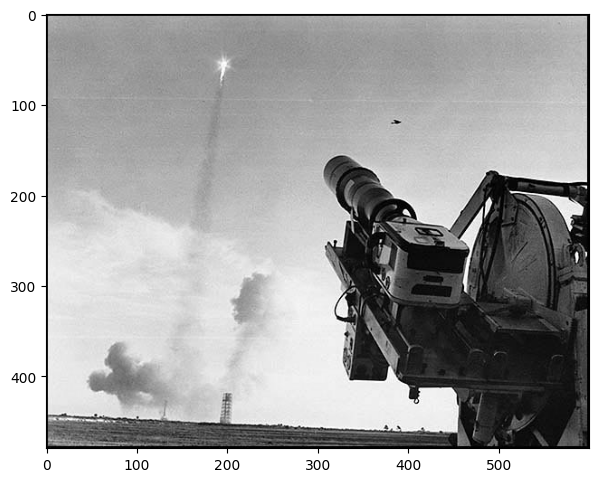

In [3]:
# Read the image.
image = cv2.imread('/content/cv2/Mod1/Apollo-8-Launch.jpg', cv2.IMREAD_COLOR)

# Display the original image.
plt.figure(figsize = [7, 7])
plt.imshow(image);
print(image.shape)

In [4]:
yellow  = (0, 255, 255)
red     = (0, 0, 255)
magenta = (255, 0, 255)
green   = (0, 255, 0)

In [5]:
# Make a copy of the original image.
image_line = image.copy()

In [6]:
# Draw a yellow line (using: cv2.LINE_8)
# image_line = cv2.line(image_line, (0, 445), (450, 465), yellow, thickness=3, lineType=cv2.LINE_8)

image_line = cv2.line(image_line, (0, 445), (450, 465), (0, 255, 0), thickness=6, lineType=cv2.LINE_8)

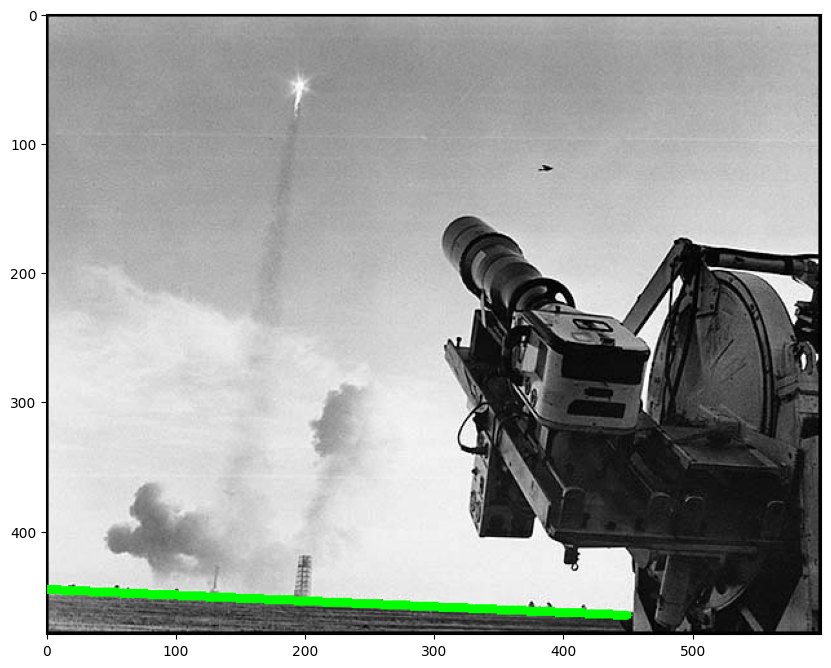

In [7]:
# Display the annotated image.
plt.figure(figsize = [10, 10])
plt.imshow(image_line[:, :, ::-1]);

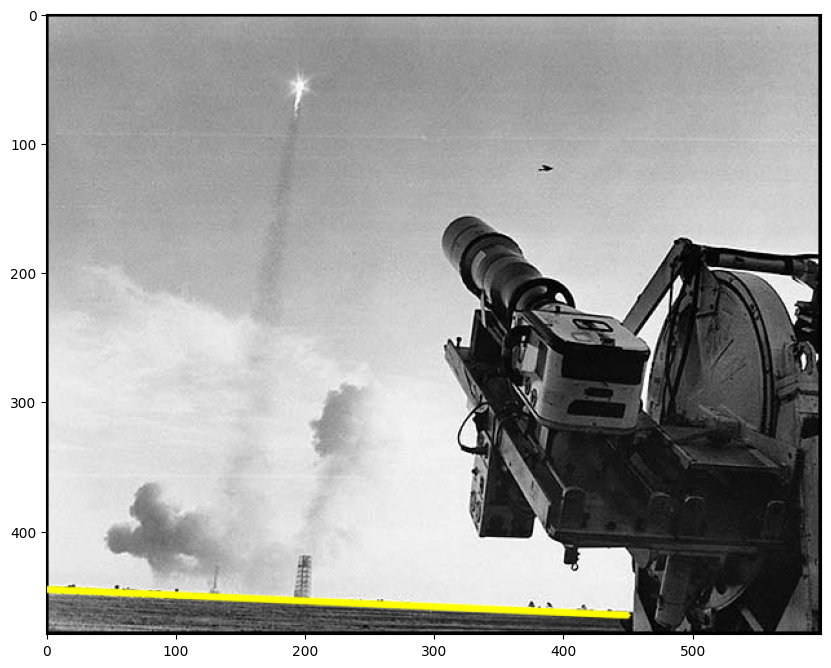

In [8]:
# Make a copy of the original image.
image_line_aa = image.copy()

# Draw a yellow line (using: cv2.LINE_AA)
image_line_aa = cv2.line(image_line_aa, (0, 445), (450, 465), yellow, thickness=3, lineType=cv2.LINE_AA)

# Display the annotated image.
plt.figure(figsize = [10, 10])
plt.imshow(image_line_aa[:, :, ::-1]);

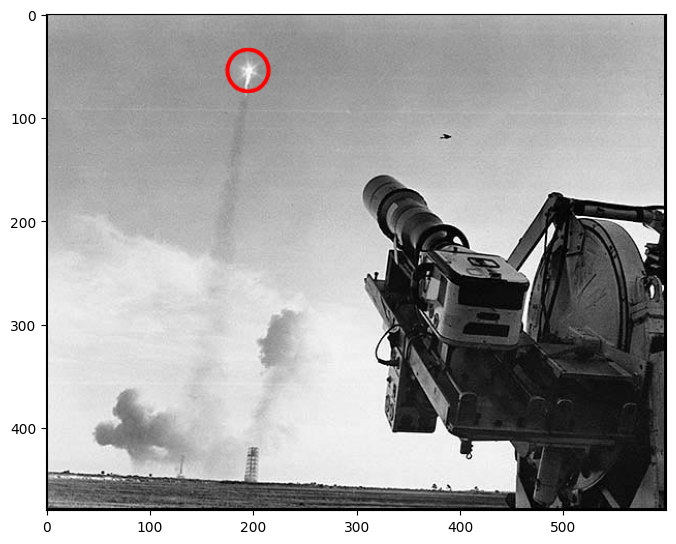

In [9]:
# Make a copy of the original image.
image_circle = image.copy()

# Draw a red circle.
image_circle = cv2.circle(image_circle, (195, 55), 20, red, thickness = 2, lineType = cv2.LINE_AA)

# Display the annotated image.
plt.figure(figsize = [8, 8])
plt.imshow(image_circle[:, :, ::-1]);

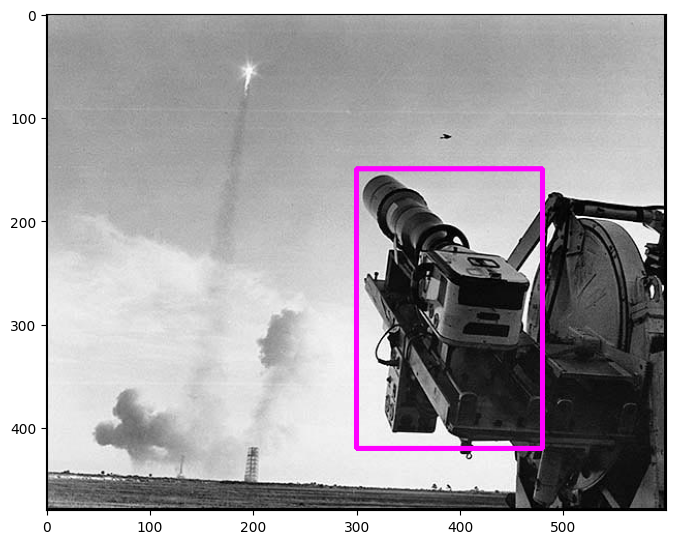

In [10]:
# Make a copy of the original image.
image_rectangle = image.copy()

# Draw a magenta rectangle.
image_rectangle = cv2.rectangle(image_rectangle, (300, 150), (480, 420), magenta, thickness = 3, lineType = cv2.LINE_8)

# Display the annotated image.
plt.figure(figsize = [8, 8])
plt.imshow(image_rectangle[:, :, ::-1]);

Original Image:


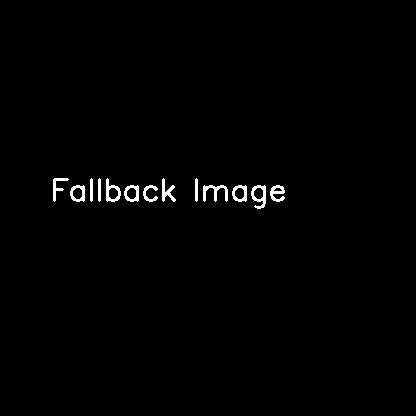

Blob Visualization:


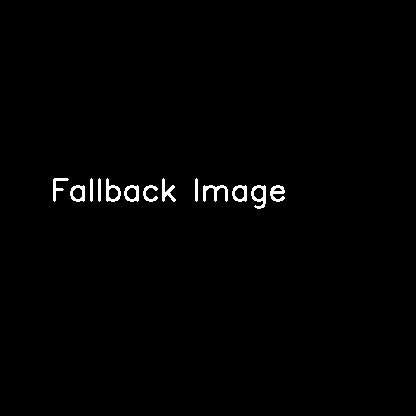

Blob shape=(1, 3, 416, 416)
Forward propagation time = 3.9504 seconds
Detection completed successfully!


In [11]:
# Downgrade OpenCV to a stable 4.x version to restore the Darknet importer
!pip install -q "opencv-python>=4.8.0,<5.0.0" "opencv-python-headless>=4.8.0,<5.0.0"

# Download YOLO weights, config, and coco names if they do not exist
!wget -q -N "/content/yolov3.cfg"
!wget -q -N "/content/yolov3.weights"
!wget -q -N "/content/coco.names"

# YOLO object detection
import cv2 as cv
import numpy as np
import time
from google.colab.patches import cv2_imshow
import os

# Check if image exists, otherwise write a dummy image or use an existing one
image_path = '/content/horse.jpg'
if not os.path.exists(image_path):
    # Create a dummy dark image with a white square as a fallback
    img = np.zeros((416, 416, 3), dtype=np.uint8)
    cv.putText(img, 'Fallback Image', (50, 200), cv.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
else:
    img = cv.imread(image_path)

print("Original Image:")
cv2_imshow(img)

# Give the configuration and weight files for the model and load the network using the robust readNet function
net = cv.dnn.readNet('yolov3.weights', 'yolov3.cfg')
net.setPreferableBackend(cv.dnn.DNN_BACKEND_OPENCV)
net.setPreferableTarget(cv.dnn.DNN_TARGET_CPU)

ln = net.getLayerNames()
# Compatibility layer output name extraction
try:
    unconnected_layers = net.getUnconnectedOutLayers()
    if len(unconnected_layers.shape) == 1:
        out_names = [ln[i - 1] for i in unconnected_layers]
    else:
        out_names = [ln[i[0] - 1] for i in unconnected_layers]
except Exception:
    out_names = net.getUnconnectedOutLayersNames()

# construct a blob from the image
blob = cv.dnn.blobFromImage(img, 1/255.0, (416, 416), swapRB=True, crop=False)
r = blob[0, 0, :, :]

print("Blob Visualization:")
cv2_imshow(r * 255)
print(f'Blob shape={blob.shape}')

net.setInput(blob)
t0 = time.time()
outputs = net.forward(out_names)
t = time.time()

print(f'Forward propagation time = {t-t0:.4f} seconds')
print("Detection completed successfully!")

In [12]:
net.setInput(blob)
t0 = time.time()
outputs = net.forward(ln)
t = time.time()

In [13]:
net.setInput(blob)
outputs = net.forward(ln)

In [18]:
# Make a copy of the original image.
image_text = image.copy()

# Add text to the image.
text = 'Apollo 8 Saturn V Launch, 21 Dec 1968'
font_face = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 0.8
font_color = green
font_thickness = 1

In [19]:
image_text = cv2.putText(image_text, text, (45, 30), font_face, font_scale, font_color, font_thickness, cv2.LINE_AA)

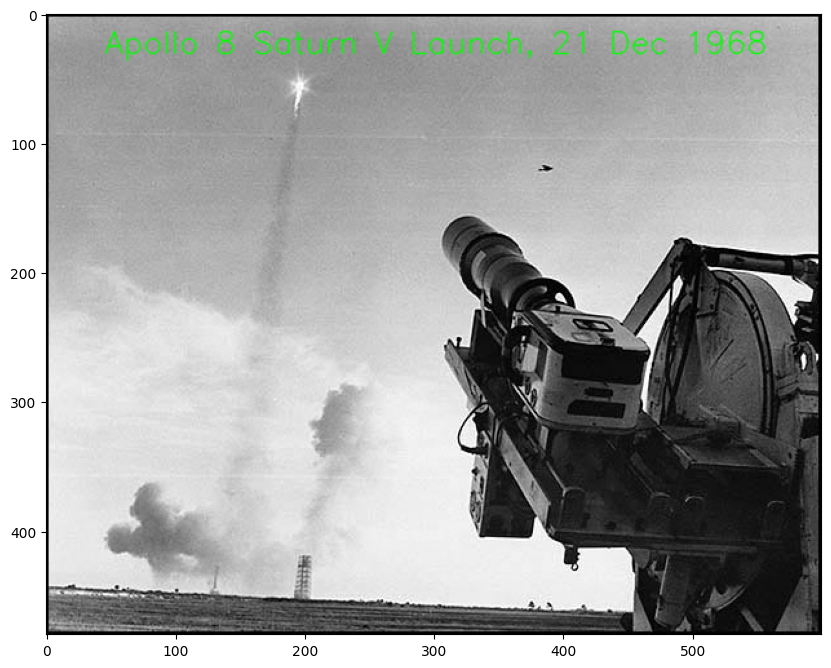

In [20]:
# Display the annotated image.
plt.figure(figsize = [10, 10])
plt.imshow(image_text[:, :, ::-1]);

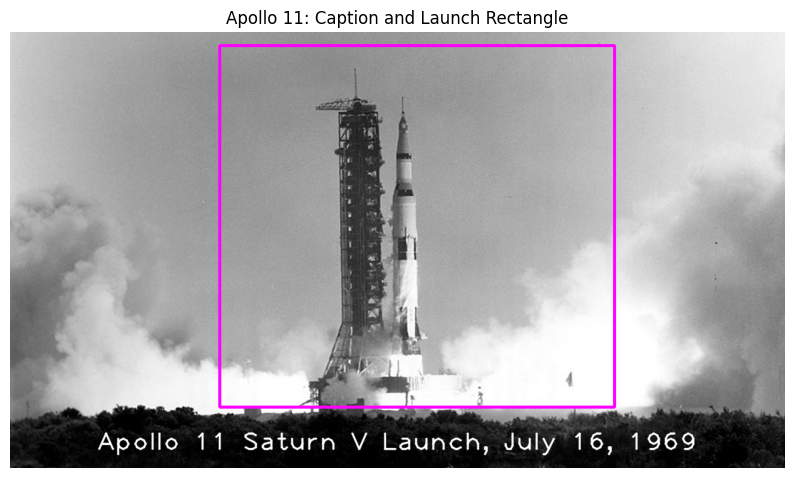

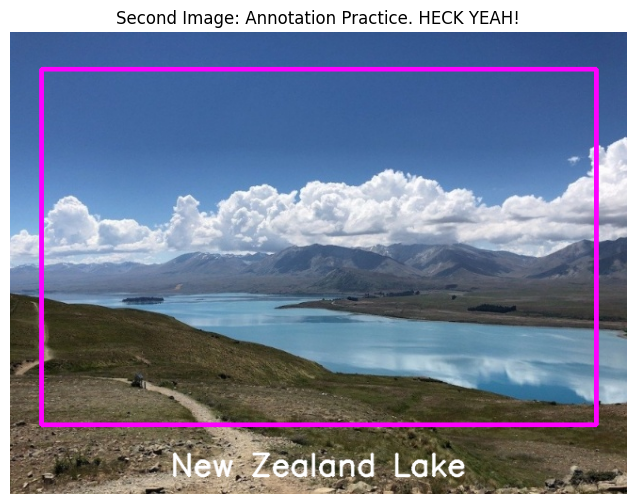

In [22]:
# HOMEWORK 1: Annotate Apollo 11.
from pathlib import Path

apollo_path = Path('/content/cv2/Mod1/Apollo-11-launch.jpg')
if not apollo_path.exists():
    matches = list(Path('/content/cv2').rglob('Apollo-11-launch.jpg'))
    if not matches:
        raise FileNotFoundError('Apollo-11-launch.jpg not found. Run the git clone cell first.')
    apollo_path = matches[0]
apollo11 = cv2.imread(str(apollo_path), cv2.IMREAD_COLOR)
if apollo11 is None:
    raise ValueError(f'Could not read {apollo_path}')

annotated_apollo = apollo11.copy()
h, w = annotated_apollo.shape[:2]
text = 'Apollo 11 Saturn V Launch, July 16, 1969'
font_face = cv2.FONT_HERSHEY_PLAIN
font_scale = max(0.8, w / 450)
font_thickness = max(1, round(w / 550))
(text_w, text_h), baseline = cv2.getTextSize(text, font_face, font_scale, font_thickness)

# Fit the caption to the image width, then center it in the dark lower area.
if text_w > 0.95 * w:
    font_scale *= 0.95 * w / text_w
    (text_w, text_h), baseline = cv2.getTextSize(text, font_face, font_scale, font_thickness)
text_x = (w - text_w) // 2
text_y = h - max(8, round(h * 0.04))
cv2.putText(annotated_apollo, text, (text_x, text_y), font_face,
            font_scale, (255, 255, 255), font_thickness, cv2.LINE_AA)

# Magenta rectangle around the central launch-tower/rocket region.
# Coordinates are proportional to the image dimensions; adjust if needed.
rect_color = magenta
cv2.rectangle(annotated_apollo, (round(0.27*w), round(0.03*h)),
              (round(0.78*w), round(0.86*h)), rect_color, 3)
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(annotated_apollo, cv2.COLOR_BGR2RGB))
plt.title('Apollo 11: Caption and Launch Rectangle')
plt.axis('off')
plt.show()

# Repeat the annotation technique on a second image selected from the repository.
second_path = Path('/content/cv2/Mod2/new-zealand-lake.jpg')
second = cv2.imread(str(second_path), cv2.IMREAD_COLOR)
if second is None:
    raise FileNotFoundError(f'Could not read {second_path}; run the clone cell first.')
my_image = second.copy()
h2, w2 = my_image.shape[:2]
cv2.rectangle(my_image, (round(.05*w2), round(.08*h2)),
              (round(.95*w2), round(.85*h2)), magenta, 3)
my_text = 'New Zealand Lake'
scale = max(0.7, w2/600)
(sz, _bl) = cv2.getTextSize(my_text, cv2.FONT_HERSHEY_SIMPLEX, scale, 2)
cv2.putText(my_image, my_text, ((w2-sz[0])//2, h2-round(.04*h2)),
            cv2.FONT_HERSHEY_SIMPLEX, scale, (255,255,255), 2, cv2.LINE_AA)
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(my_image, cv2.COLOR_BGR2RGB))
plt.title('Second Image: Annotation Practice. HECK YEAH!')
plt.axis('off')
plt.show()

MATRIX ALGEBRA


In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image

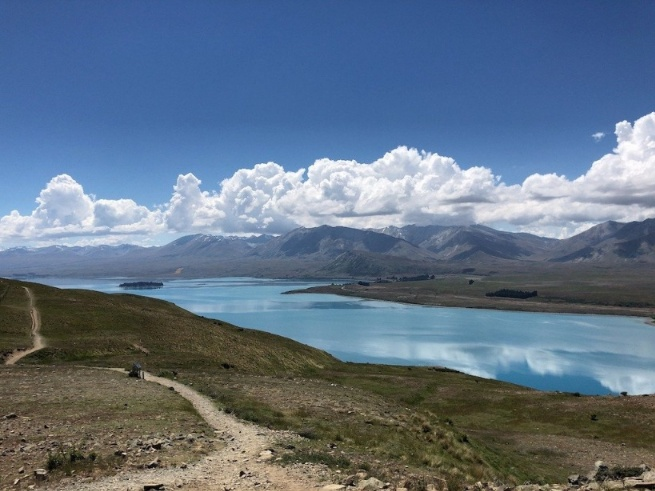

In [24]:
image = '/content/cv2/Mod2/new-zealand-lake.jpg'
img = cv2.imread(image, cv2.IMREAD_COLOR)

# Display the image.
Image(filename=image, width='400')

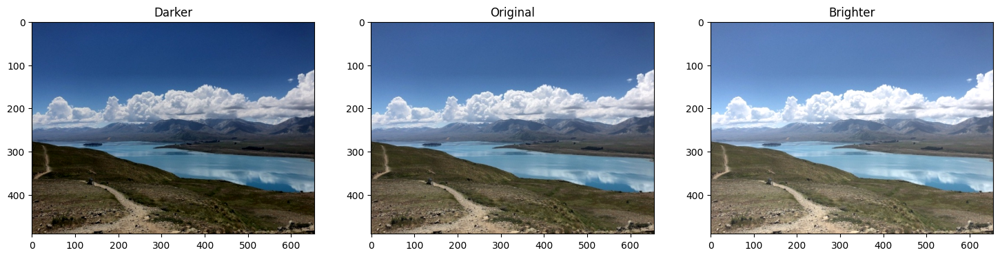

In [25]:
# Create a matrix with constant intensity.
matrix = np.ones(img.shape, dtype = 'uint8') * 30

# Create brighter and darker images.
img_brighter = cv2.add(img, matrix)
img_darker   = cv2.subtract(img, matrix)

# Display the images
plt.figure(figsize = [18,5])
plt.subplot(131); plt.imshow(img_darker[:, :, ::-1]);   plt.title('Darker')
plt.subplot(132); plt.imshow(img[:, :, ::-1]);          plt.title('Original')
plt.subplot(133); plt.imshow(img_brighter[:, :, ::-1]); plt.title('Brighter');

In [26]:
# Two pixels: one medium, one already bright.
pixels = np.array([[200, 250]], dtype = 'uint8')
boost  = np.array([[30, 30]],   dtype = 'uint8')

print('NumPy  + :', pixels + boost)
print('OpenCV add:', cv2.add(pixels, boost))

NumPy  + : [[230  24]]
OpenCV add: [[230 255]]


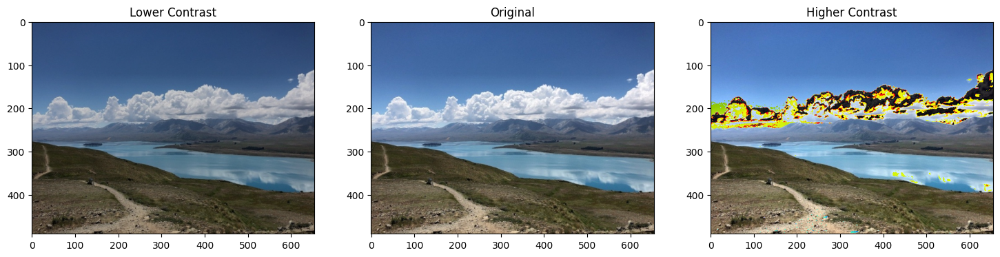

In [27]:
# Create matrices with a constant scale factor.
matrix1 = np.ones(img.shape) * 0.8
matrix2 = np.ones(img.shape) * 1.2

# Create lower and higher contrast images.
img_lower  = np.uint8(cv2.multiply(np.float64(img), matrix1))
img_higher = np.uint8(cv2.multiply(np.float64(img), matrix2))

# Display the images.
plt.figure(figsize = [18,5])
plt.subplot(131); plt.imshow(img_lower[:, :, ::-1]);  plt.title('Lower Contrast')
plt.subplot(132); plt.imshow(img[:, :, ::-1]);        plt.title('Original')
plt.subplot(133); plt.imshow(img_higher[:, :, ::-1]); plt.title('Higher Contrast');

In [28]:
# Three pixel values, stretched by 1.2 in floating point.
values  = np.array([[150.0, 100.0, 230.0]])
stretch = cv2.multiply(values, np.ones(values.shape) * 1.2)

print('As floats       :', stretch)
print('np.uint8()      :', np.uint8(stretch))
print('Clip, then uint8:', np.uint8(np.clip(stretch, 0, 255)))

As floats       : [[180. 120. 276.]]
np.uint8()      : [[180 120  20]]
Clip, then uint8: [[180 120 255]]


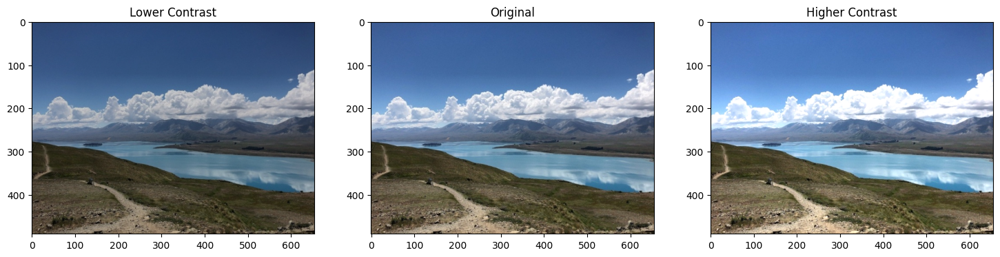

In [29]:
# Create matrices with a constant scale factor.
matrix1 = np.ones(img.shape) * 0.8
matrix2 = np.ones(img.shape) * 1.2

# Create lower and higher contrast images.
img_lower   = np.uint8(cv2.multiply(np.float64(img), matrix1))
img_higher  = np.uint8(np.clip(cv2.multiply(np.float64(img), matrix2) , 0, 255))

# Display the images.
plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(img_lower[:, :, ::-1]);  plt.title('Lower Contrast')
plt.subplot(132); plt.imshow(img[:, :, ::-1]);        plt.title('Original')
plt.subplot(133); plt.imshow(img_higher[:, :, ::-1]); plt.title('Higher Contrast');

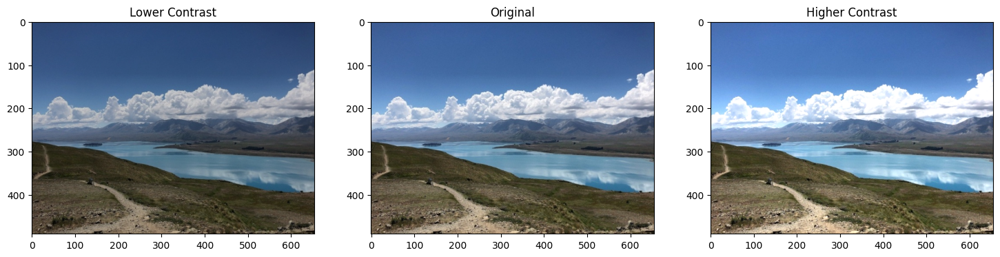

In [30]:
# Create matrices with a constant scale factor.
matrix_ones = np.ones(img.shape, dtype = 'float64')

# Create lower and higher contrast images.
img_lower   = np.uint8(cv2.multiply(np.float64(img), matrix_ones, scale = 0.8))
img_higher  = np.uint8(np.clip(cv2.multiply(np.float64(img), matrix_ones, scale = 1.2) , 0, 255))

# Display the images.
plt.figure(figsize = [18,5])
plt.subplot(131); plt.imshow(img_lower[:, :, ::-1]);  plt.title('Lower Contrast')
plt.subplot(132); plt.imshow(img[:, :, ::-1]);        plt.title('Original')
plt.subplot(133); plt.imshow(img_higher[:, :, ::-1]); plt.title('Higher Contrast');

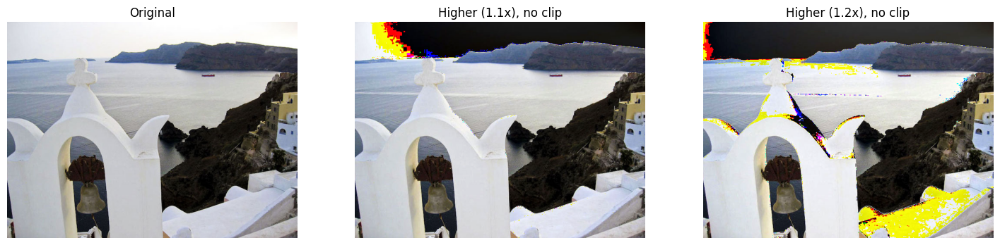

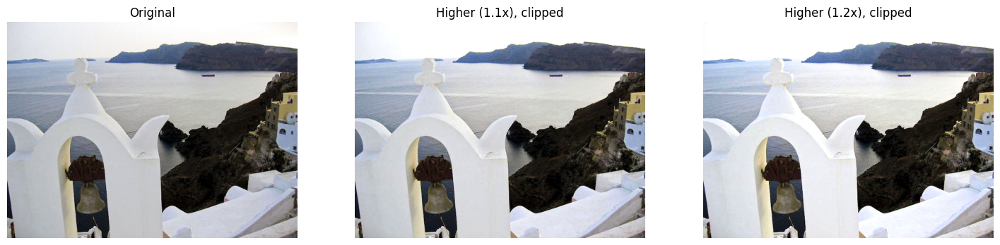

In [31]:
# HOMEWORK 2: Santorini contrast, before and after fixing overflow.
from pathlib import Path
matches = list(Path('/content/cv2').rglob('Santorini.jpg'))
if not matches:
    raise FileNotFoundError('Santorini.jpg not found. Run the git clone cell first.')
image = str(matches[0])
img = cv2.imread(image, cv2.IMREAD_COLOR)
if img is None:
    raise ValueError(f'Could not read {image}')
matrix_ones = np.ones(img.shape, dtype=np.float64)

# Without the overflow fix: casting values above 255 to uint8 wraps around.
img_higher1 = np.uint8(cv2.multiply(np.float64(img), matrix_ones, scale=1.1))
img_higher2 = np.uint8(cv2.multiply(np.float64(img), matrix_ones, scale=1.2))
plt.figure(figsize=(18,5))
plt.subplot(131); plt.imshow(img[:, :, ::-1]);         plt.title('Original'); plt.axis('off')
plt.subplot(132); plt.imshow(img_higher1[:, :, ::-1]); plt.title('Higher (1.1x), no clip'); plt.axis('off')
plt.subplot(133); plt.imshow(img_higher2[:, :, ::-1]); plt.title('Higher (1.2x), no clip'); plt.axis('off')
plt.show()

# With the overflow fix: clip to [0,255] before converting to uint8.
img_higher1 = np.uint8(np.clip(cv2.multiply(np.float64(img), matrix_ones, scale=1.1), 0, 255))
img_higher2 = np.uint8(np.clip(cv2.multiply(np.float64(img), matrix_ones, scale=1.2), 0, 255))
plt.figure(figsize=(18,5))
plt.subplot(131); plt.imshow(img[:, :, ::-1]);         plt.title('Original'); plt.axis('off')
plt.subplot(132); plt.imshow(img_higher1[:, :, ::-1]); plt.title('Higher (1.1x), clipped'); plt.axis('off')
plt.subplot(133); plt.imshow(img_higher2[:, :, ::-1]); plt.title('Higher (1.2x), clipped'); plt.axis('off')
plt.show()

Thresholding Images with OpenCV

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['image.cmap'] = 'gray'

In [33]:
# Five pixel brightness values, from dark to bright.
pixels = np.array([[100, 164, 165, 166, 250]], dtype = 'uint8')

retval, binary     = cv2.threshold(pixels, 165, 255, cv2.THRESH_BINARY)
retval, binary_inv = cv2.threshold(pixels, 165, 255, cv2.THRESH_BINARY_INV)

print('retval        :', retval)
print('Original      :', pixels)
print('THRESH_BINARY :', binary)
print('BINARY_INV    :', binary_inv)

retval        : 165.0
Original      : [[100 164 165 166 250]]
THRESH_BINARY : [[  0   0   0 255 255]]
BINARY_INV    : [[255 255 255   0   0]]


Text(0.5, 1.0, 'Thresholded')

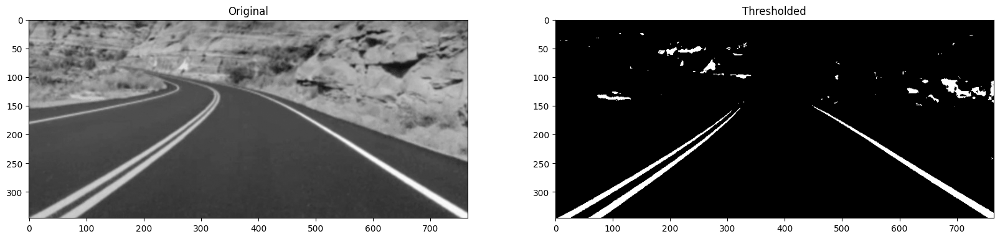

In [34]:
# Read image in grayscale.
img = cv2.imread('/content/cv2/Mod2/road_lanes.png', cv2.IMREAD_GRAYSCALE)

# Perform binary thresholding.
retval, img_thresh = cv2.threshold(img, 165, 100, cv2.THRESH_BINARY)

# Display the images.
plt.figure(figsize = [20, 8])
plt.subplot(121); plt.imshow(img); plt.title('Original')
plt.subplot(122); plt.imshow(img_thresh); plt.title('Thresholded')

Text(0.5, 1.0, 'Thresholded')

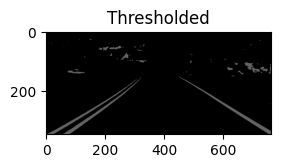

In [35]:
plt.subplot(122); plt.imshow(img_thresh, cmap='gray', vmin=0, vmax=255); plt.title('Thresholded')

In [36]:
# Read the original image.
img = cv2.imread('/content/cv2/Mod2/Piano_Sheet_Music.png', cv2.IMREAD_GRAYSCALE)

# Perform global thresholding.
retval, img_thresh_gbl_1 = cv2.threshold(img, 50, 255, cv2.THRESH_BINARY)

# Perform global thresholding.
retval, img_thresh_gbl_2 = cv2.threshold(img, 130, 255, cv2.THRESH_BINARY)

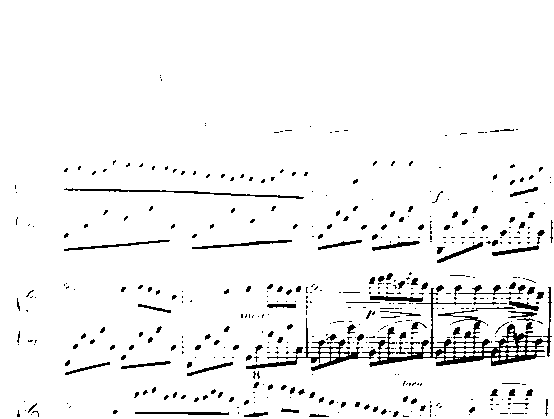

In [37]:
from google.colab.patches import cv2_imshow
cv2_imshow(img_thresh_gbl_1)

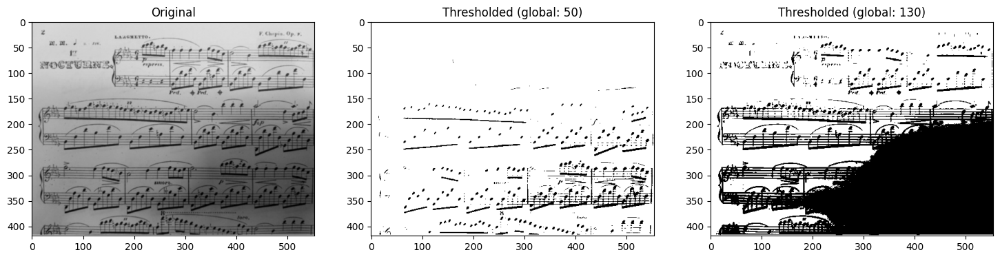

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=[18, 5])
plt.subplot(131); plt.imshow(img, cmap='gray');              plt.title('Original')
plt.subplot(132); plt.imshow(img_thresh_gbl_1, cmap='gray'); plt.title('Thresholded (global: 50)')
plt.subplot(133); plt.imshow(img_thresh_gbl_2, cmap='gray'); plt.title('Thresholded (global: 130)')
plt.show()

In [39]:
# Perform adaptive thresholding.
img_thresh_adp = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 13, 7)

Text(0.5, 1.0, 'Thresholded (adaptive)')

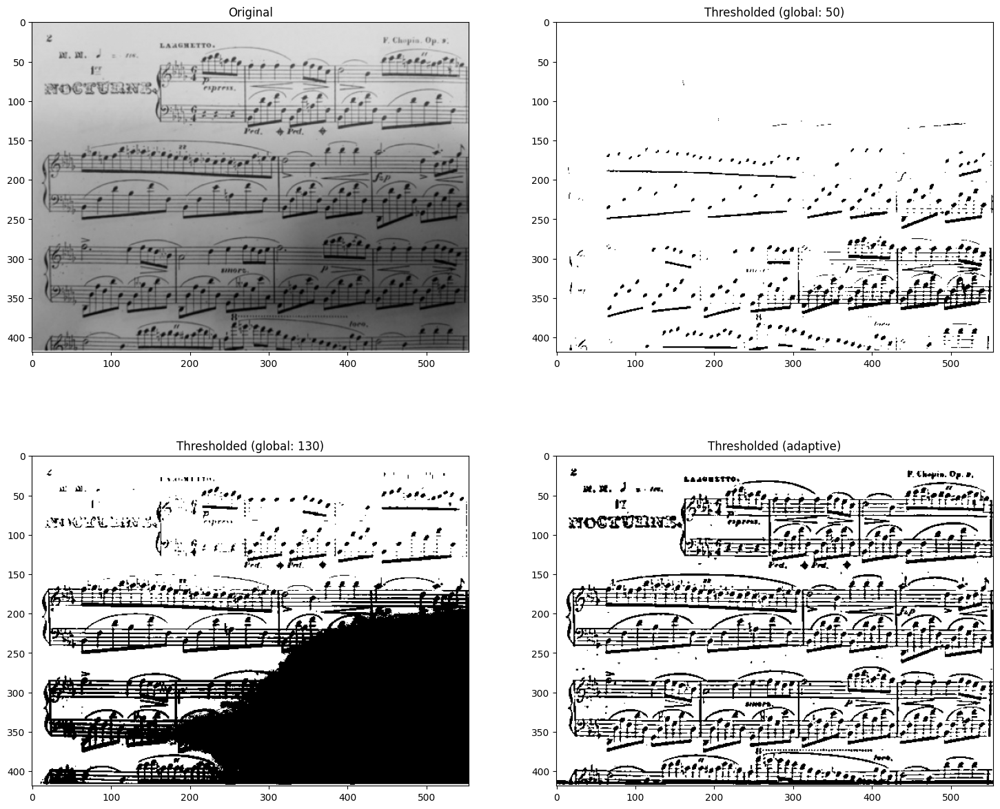

In [40]:
# Display the images.
plt.figure(figsize = [18, 15])
plt.subplot(221); plt.imshow(img);              plt.title('Original')
plt.subplot(222); plt.imshow(img_thresh_gbl_1); plt.title('Thresholded (global: 50)')
plt.subplot(223); plt.imshow(img_thresh_gbl_2); plt.title('Thresholded (global: 130)')
plt.subplot(224); plt.imshow(img_thresh_adp);   plt.title('Thresholded (adaptive)')

Automatically selected global threshold: 131


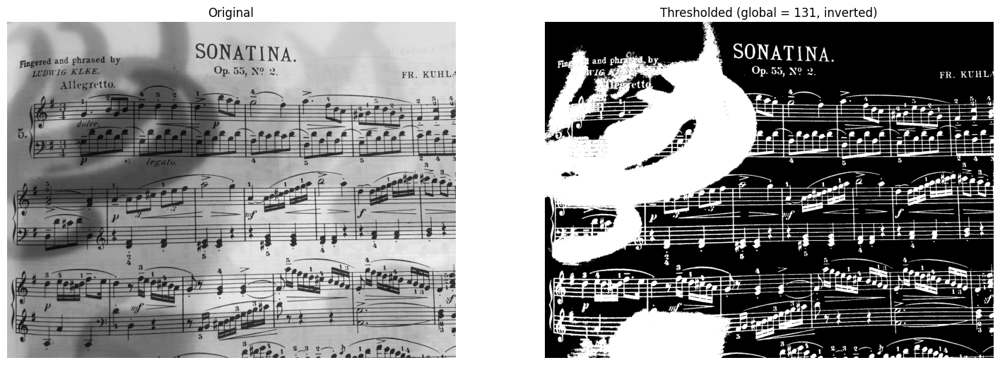

In [41]:
# HOMEWORK 3: Global thresholding of sheet music.
from pathlib import Path
matches = list(Path('/content/cv2').rglob('Sheet_Music_Test-1.jpg'))
if not matches:
    raise FileNotFoundError('Sheet_Music_Test-1.jpg not found. Run the git clone cell first.')
img = cv2.imread(str(matches[0]), cv2.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError(f'Could not read {matches[0]}')

# Otsu's method selects one global threshold from the image histogram.
# cv2.THRESH_BINARY_INV makes darker notes/staff lines white (255).
retval, img_thresh = cv2.threshold(img, 0, 255,
                                  cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print(f'Automatically selected global threshold: {retval:.0f}')
plt.figure(figsize=(18, 8))
plt.subplot(121); plt.imshow(img, cmap='gray', vmin=0, vmax=255); plt.title('Original'); plt.axis('off')
plt.subplot(122); plt.imshow(img_thresh, cmap='gray', vmin=0, vmax=255)
plt.title(f'Thresholded (global = {retval:.0f}, inverted)'); plt.axis('off')
plt.show()

EXPLANATION:

Why does global thresholding struggle at times?

A single global threshold uses the same brightness cutoff across the whole sheet, even where shadows darken the paper. This can mistake shadows for notes or lose lighter musical marks. Adaptive thresholding chooses a different cutoff from each small neighborhood, helping separate the notation from uneven lighting.

In [57]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
import matplotlib
%matplotlib inline
from IPython.display import Image
plt.rcParams['image.cmap'] = 'gray'

(2436, 2623, 4)


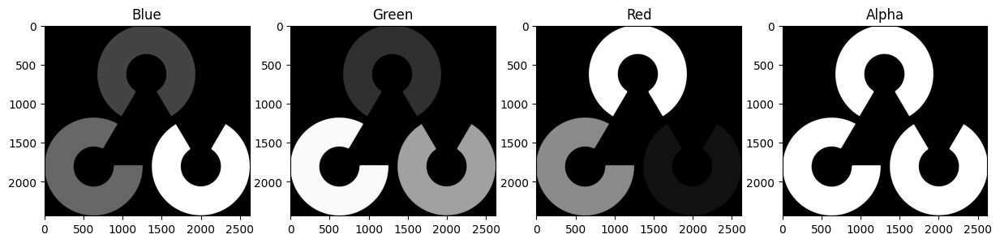

In [58]:
# Read the PNG image using: cv2.IMREAD_UNCHANGED to retain the alpha channel.
img = cv2.imread('/content/cv2/Mod2/opencv_logo.png', cv2.IMREAD_UNCHANGED)

print(img.shape)

# Split the channels.
b, g, r, a = cv2.split(img)

# Display eazch of the channels.
plt.figure(figsize = (15,15))
plt.subplot(141); plt.imshow(b); plt.title('Blue')
plt.subplot(142); plt.imshow(g); plt.title('Green')
plt.subplot(143); plt.imshow(r); plt.title('Red')
plt.subplot(144); plt.imshow(a); plt.title('Alpha');

Shape of the color image:  (640, 640, 3)


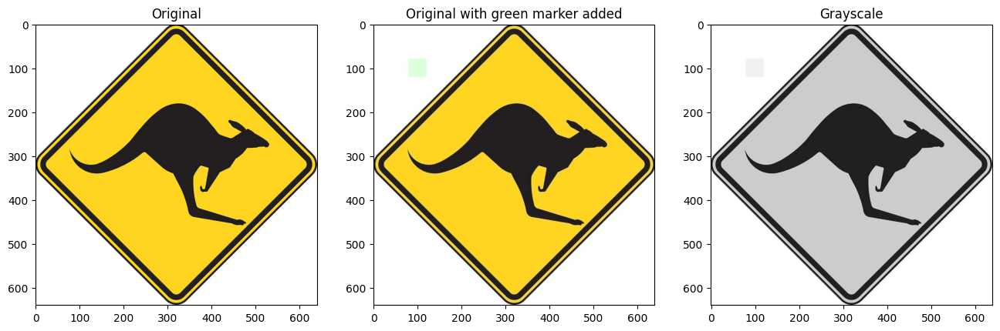

In [60]:
# Read the original and modified JPG images of the kangaroo sign.
img_kang_org = cv2.imread("/content/cv2/Mod2/kangaroo.jpg",cv2.IMREAD_COLOR)
img_kang = cv2.imread('/content/cv2/Mod2/kangaroo_sign_with_green_marker.jpg',cv2.IMREAD_COLOR)

# For reference: Code used to add light green marker to original image of the kangaroo sign.
# img_kang_org[80:120,80:120,0] = 220
# img_kang_org[80:120,80:120,1] = 255
# img_kang_org[80:120,80:120,2] = 220
# cv2.imwrite('kangaroo_sign_with_green_marker.jpg', img_kang_org)

# Print the image shapes to verify the channels.
print('Shape of the color image: ', img_kang.shape)

# Convert the image to gray scale.
img_kang_gray = cv2.cvtColor(img_kang, cv2.COLOR_BGR2GRAY)

plt.figure(figsize = (16,10))
plt.subplot(131); plt.imshow(img_kang_org[:, :, ::-1]); plt.title('Original')
plt.subplot(132); plt.imshow(img_kang[:, :, ::-1]);     plt.title('Original with green marker added')
plt.subplot(133); plt.imshow(img_kang_gray);            plt.title('Grayscale');

In [61]:
ret1, thresh1 = cv2.threshold(img_kang_gray, 150, 255, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_kang_gray, 230, 255, cv2.THRESH_BINARY)
ret3, thresh3 = cv2.threshold(img_kang_gray, 230, 200, cv2.THRESH_BINARY)  # Note max value of mask is set to 200

In [62]:
kang_inv_mask_full = cv2.bitwise_not(thresh2)  # Fully transparent
kang_inv_mask_semi = cv2.bitwise_not(thresh3)  # Semi-transparent (due to max value of thresh3 = 200)

# Print the pixel itensity of the inverted binary masks at the location (100,100).
print('Inverse Mask (full) at (100,100): ', kang_inv_mask_full[100,100])
print('Inverse Mask (semi) at (100,100): ', kang_inv_mask_semi[100,100])

Inverse Mask (full) at (100,100):  0
Inverse Mask (semi) at (100,100):  55


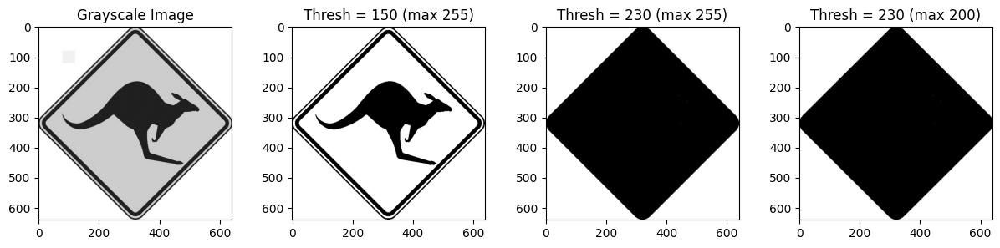

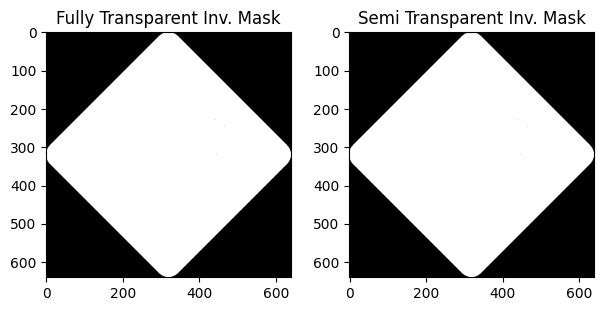

In [63]:
plt.figure(figsize = (15, 3))
plt.subplot(141); plt.imshow(img_kang_gray);  plt.title('Grayscale Image')
plt.subplot(142); plt.imshow(thresh1); plt.title('Thresh = 150 (max 255)')
plt.subplot(143); plt.imshow(thresh2); plt.title('Thresh = 230 (max 255)')
plt.subplot(144); plt.imshow(thresh3); plt.title('Thresh = 230 (max 200)')

plt.figure(figsize = (15, 7))
plt.subplot(245); plt.imshow(kang_inv_mask_full); plt.title('Fully Transparent Inv. Mask')
plt.subplot(246); plt.imshow(kang_inv_mask_semi); plt.title('Semi Transparent Inv. Mask');

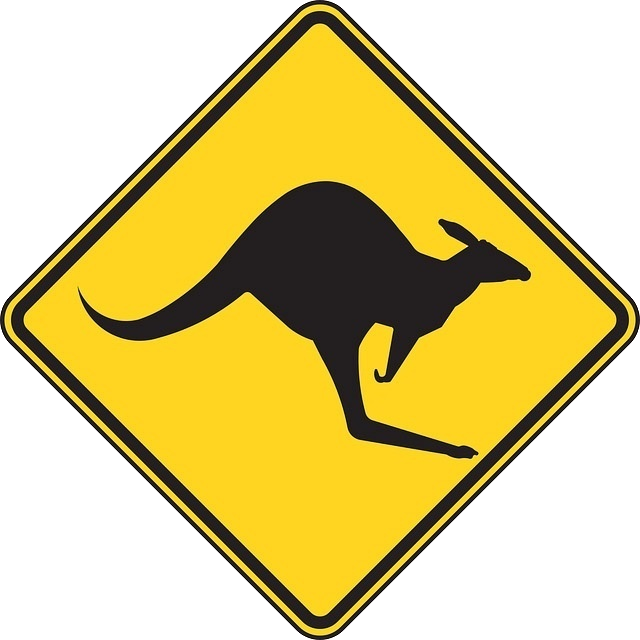

In [64]:
# Split the color channels from the original image.
bk, gk, rk = cv2.split(img_kang)

# Add the "mask" as the 4th channel.
mat = [bk, gk, rk, kang_inv_mask_full]

# Use the merge() function to create a single multi-channel array.
kangaroo_transparent = cv2.merge(mat)

# Save the transparent image as a PNG file to preserve the alpha channel.
cv2.imwrite('kangaroo_alpha_full.png', kangaroo_transparent)

# Display the PNG file we just created.
Image(filename = "kangaroo_alpha_full.png", width = '300')

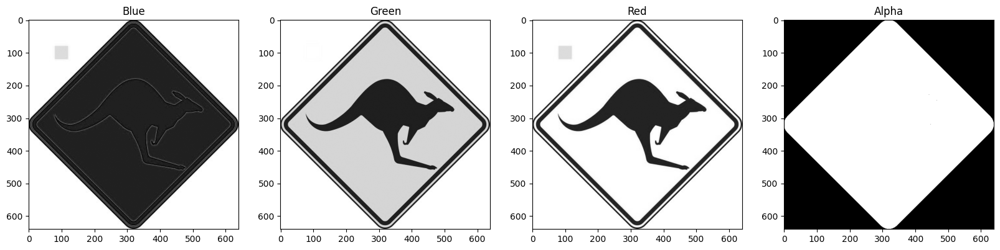

In [65]:
# Read the PNG image using: cv2.IMREAD_UNCHANGED to retain the alpha channel.
img = cv2.imread('kangaroo_alpha_full.png', cv2.IMREAD_UNCHANGED)

# Split the channels.
b, g, r, a = cv2.split(img)

# Display each of the channels.
plt.figure(figsize = (20,15))
plt.subplot(141); plt.imshow(b); plt.title('Blue')
plt.subplot(142); plt.imshow(g); plt.title('Green')
plt.subplot(143); plt.imshow(r); plt.title('Red')
plt.subplot(144); plt.imshow(a); plt.title('Alpha');

Shape: (640, 640, 4)
Alpha at (100,100): 128


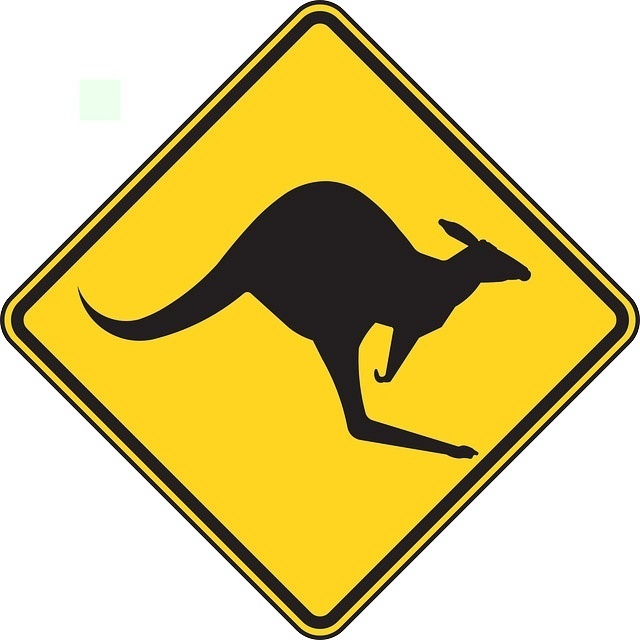

In [66]:
# Threshold with a max value of 127, so that NOT gives 255 - 127 = 128 in the background.
# Or get your own image and use the alpha channel (get a png) and make the bg transparent
ret4, thresh4 = cv2.threshold(img_kang_gray, 230, 127, cv2.THRESH_BINARY)
kang_inv_mask_half = cv2.bitwise_not(thresh4)

# Attach the mask as the alpha channel and save as PNG.
bk, gk, rk = cv2.split(img_kang)
kangaroo_half = cv2.merge([bk, gk, rk, kang_inv_mask_half])
cv2.imwrite('kangaroo_alpha_half.png', kangaroo_half)

# Prove it: read the file back and check the alpha value in the background.
img_check = cv2.imread('kangaroo_alpha_half.png', cv2.IMREAD_UNCHANGED)
print('Shape:', img_check.shape)
print('Alpha at (100,100):', img_check[100, 100, 3])

# Display the PNG file we just created.
Image(filename = "kangaroo_alpha_half.png", width = '300')

Saved: new_zealand_lake_transparent.png | Shape (with alpha): (491, 655, 4)


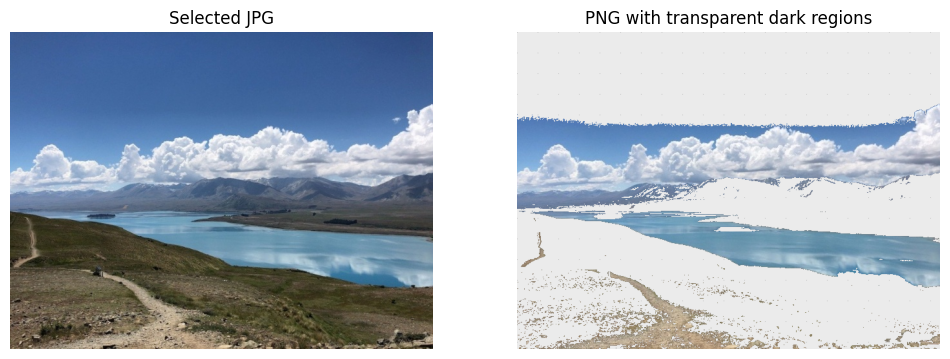

In [67]:
# HOMEWORK 4 (second image): Add a transparent background to a different JPG.
# This example uses the New Zealand lake photo from the cloned repository.
from pathlib import Path
own_path = Path('/content/cv2/Mod2/new-zealand-lake.jpg')
own_bgr = cv2.imread(str(own_path), cv2.IMREAD_COLOR)
if own_bgr is None:
    raise FileNotFoundError(f'Could not read {own_path}; run the clone cell first.')
own_gray = cv2.cvtColor(own_bgr, cv2.COLOR_BGR2GRAY)

# Threshold the luminance, keeping brighter regions opaque and darker regions transparent.
# This is a simple demonstration mask rather than precise foreground segmentation.
threshold_value, own_alpha = cv2.threshold(own_gray, 115, 255, cv2.THRESH_BINARY)
own_bgra = cv2.merge([own_bgr[:, :, 0], own_bgr[:, :, 1], own_bgr[:, :, 2], own_alpha])
output_path = 'new_zealand_lake_transparent.png'
cv2.imwrite(output_path, own_bgra)

# Verify the saved file retains an alpha channel and display transparency with a checkerboard.
check = cv2.imread(output_path, cv2.IMREAD_UNCHANGED)
print('Saved:', output_path, '| Shape (with alpha):', check.shape)
checker = np.full(own_gray.shape, 235, dtype=np.uint8)
checker[::32, ::32] = 180  # small checker marks to show transparency
alpha = check[:, :, 3:4].astype(np.float32) / 255
rgb = cv2.cvtColor(check[:, :, :3], cv2.COLOR_BGR2RGB).astype(np.float32)
background = np.repeat(checker[:, :, None], 3, axis=2).astype(np.float32)
preview = np.uint8(rgb * alpha + background * (1-alpha))
plt.figure(figsize=(12, 5))
plt.subplot(121); plt.imshow(cv2.cvtColor(own_bgr, cv2.COLOR_BGR2RGB)); plt.title('Selected JPG'); plt.axis('off')
plt.subplot(122); plt.imshow(preview); plt.title('PNG with transparent dark regions'); plt.axis('off')
plt.show()
